# Session 16 Solutions: Project 2: An Exploratory Analysis Report

Data Science with Python, Level 1, Stage 2: Working with Data

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
bikes["date"] = pd.to_datetime(bikes["date"])

## In-Class Exercises

### In-Class Exercise 1: Pick and Ask

In [2]:
# Dataset: bike_rentals.csv
# Q1 How much did rentals grow from 2023 to 2024? (date, rentals)
# Q2 How strongly does temperature drive rentals? (temp_c, rentals)
# Q3 How much do rain and wind reduce rentals? (weather, wind_kmh, rentals)
# Q4 Do working days differ from weekends and holidays? (working_day, rentals)
print("Questions written")

Questions written


### In-Class Exercise 2: Overview and Quality

In [3]:
print(bikes.shape)
print(bikes.dtypes)
print(bikes.isna().sum().sum(), bikes.duplicated().sum())
print("Impossible values:", (bikes["rentals"] < 0).sum(), (bikes["humidity"] > 100).sum())

(731, 10)
date           datetime64[us]
season                    str
holiday                  bool
weekday                   str
working_day              bool
weather                   str
temp_c                float64
humidity                int64
wind_kmh              float64
rentals                 int64
dtype: object
0 0
Impossible values: 0 0


### In-Class Exercise 3: First Question

weather
Rain      0.44
Cloudy    0.84
Clear     1.00
Name: rentals, dtype: float64


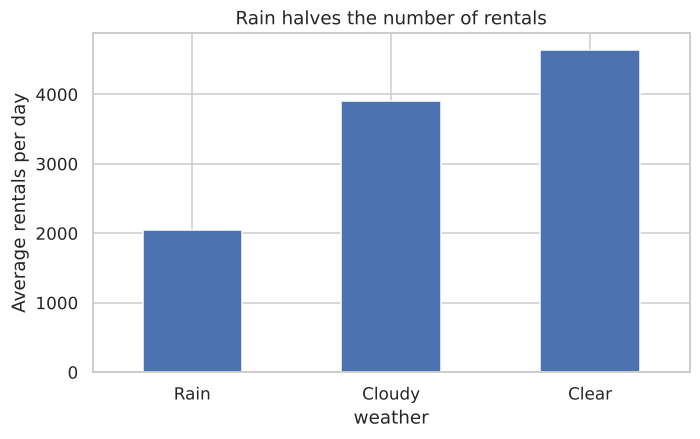

In [4]:
by_weather = bikes.groupby("weather")["rentals"].mean().sort_values()
ax = by_weather.plot(kind="bar", rot=0)
ax.set_title("Rain halves the number of rentals")
ax.set_ylabel("Average rentals per day")
plt.show()
print((by_weather / by_weather["Clear"]).round(2))

### In-Class Exercise 4: Peer Review

In [5]:
# Strengths: the questions are specific; every chart has a title that states the finding.
# Improvements: add a caveat about the missing values; sort the bars in the second chart.
print("Review written")

Review written


## Part A: Basic

### Exercise 1: Milestone 1: Questions and Data

In [6]:
# Report: What drives bike rentals in City Bikes?
# Data: bike_rentals.csv, course practice data, one row per day for 2023 and 2024.
print(bikes.shape)
print(bikes.head())

(731, 10)
        date  season  holiday    weekday  working_day weather  temp_c  humidity  wind_kmh  rentals
0 2023-01-01  Winter    False     Sunday        False   Clear     7.2        55      13.6     2544
1 2023-01-02  Winter    False     Monday         True    Rain     6.1        68      17.1     1386
2 2023-01-03  Winter    False    Tuesday         True  Cloudy     5.2        74       8.6     2578
3 2023-01-04  Winter    False  Wednesday         True   Clear    -1.6        42       1.3     1546
4 2023-01-05  Winter    False   Thursday         True  Cloudy     6.6        67      22.8     1903


### Exercise 2: Milestone 2: Data Quality

In [7]:
print(bikes.dtypes)
print("Missing:", bikes.isna().sum().sum())
print("Duplicate dates:", bikes["date"].duplicated().sum())
print("Rentals range:", bikes["rentals"].min(), "to", bikes["rentals"].max())
print("Humidity within 0 to 100:", bikes["humidity"].between(0, 100).all())
# No problems found: the data is complete, one row per day, values in sensible ranges.

date           datetime64[us]
season                    str
holiday                  bool
weekday                   str
working_day              bool
weather                   str
temp_c                float64
humidity                int64
wind_kmh              float64
rentals                 int64
dtype: object
Missing: 0
Duplicate dates: 0
Rentals range: 578 to 8178
Humidity within 0 to 100: True


## Part B: Intermediate

### Exercise 3: Milestone 3: Questions 1 and 2

`order=2` fits a curve instead of a straight line, which shows the levelling off at high temperatures.

Growth: 25.6 percent
Correlation with temperature: 0.72


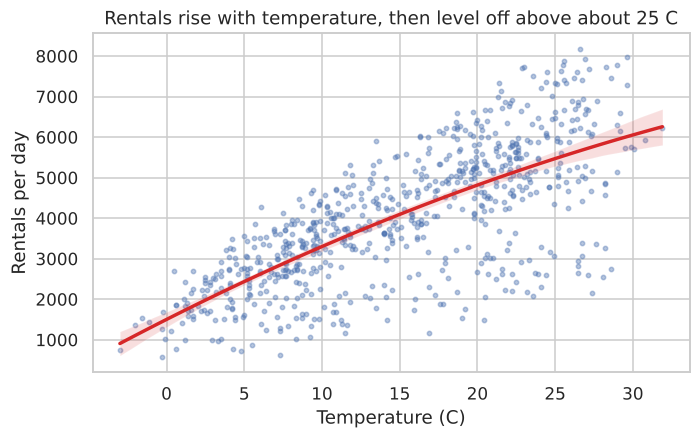

In [8]:
bikes["year"] = bikes["date"].dt.year
yearly = bikes.groupby("year")["rentals"].mean()
print(f"Growth: {(yearly[2024] / yearly[2023] - 1) * 100:.1f} percent")

sns.regplot(data=bikes, x="temp_c", y="rentals", scatter_kws={"s": 8, "alpha": 0.4}, order=2,
            line_kws={"color": "tab:red"})
plt.title("Rentals rise with temperature, then level off above about 25 C")
plt.xlabel("Temperature (C)")
plt.ylabel("Rentals per day")
plt.show()
print("Correlation with temperature:", round(bikes["temp_c"].corr(bikes["rentals"]), 2))

### Exercise 4: Milestone 4: Questions 3 and 4

wind_band
calm      4065.0
breezy    3914.0
windy     4043.0
Name: rentals, dtype: float64
working_day
False    3587.0
True     4199.0
Name: rentals, dtype: float64


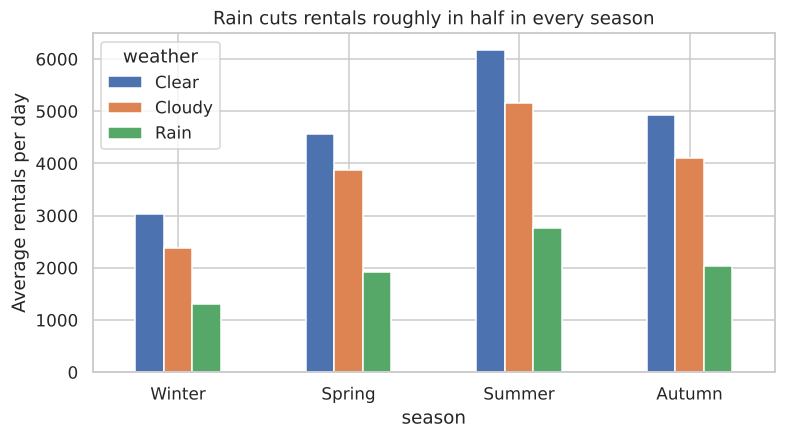

In [9]:
pt = bikes.groupby(["season", "weather"])["rentals"].mean().unstack().reindex(["Winter", "Spring", "Summer", "Autumn"])
ax = pt[["Clear", "Cloudy", "Rain"]].plot(kind="bar", rot=0, figsize=(8, 4))
ax.set_title("Rain cuts rentals roughly in half in every season")
ax.set_ylabel("Average rentals per day")
plt.show()

bikes["wind_band"] = pd.cut(bikes["wind_kmh"], [0, 10, 20, 50], labels=["calm", "breezy", "windy"], include_lowest=True)
print(bikes.groupby("wind_band", observed=True)["rentals"].mean().round(0))

print(bikes.groupby("working_day")["rentals"].mean().round(0))

## Part C: Challenge

### Exercise 5: Milestone 5: Summary and Caveats

In [10]:
summary = '''
Summary
1. Average daily rentals grew by about 25 percent from 2023 to 2024, in every month.
2. Temperature is the strongest weather driver: rentals climb steadily up to about 25 C, then level off.
3. Rain roughly halves rentals in every season; strong wind reduces them further.
4. Working days are about 17 percent busier than weekends and holidays.

Caveats
- The data is practice data for one fictional city over two years.
- Weather is recorded once per day, so short showers are not visible.
- The patterns are associations; other factors, such as events, are not in the data.
'''
print(summary)


Summary
1. Average daily rentals grew by about 25 percent from 2023 to 2024, in every month.
2. Temperature is the strongest weather driver: rentals climb steadily up to about 25 C, then level off.
3. Rain roughly halves rentals in every season; strong wind reduces them further.
4. Working days are about 17 percent busier than weekends and holidays.

Caveats
- The data is practice data for one fictional city over two years.
- Weather is recorded once per day, so short showers are not visible.
- The patterns are associations; other factors, such as events, are not in the data.



## Part D: Cumulative Project: Cafe Sales Analysis

### Exercise 6: Milestone 6: Final Check and Submission

In [11]:
# Questions 15/15, Data quality 14/15, Analysis 23/25, Charts 18/20, Story 14/15, Reproducible 10/10
print("Self-assessment done")

Self-assessment done
